# Experiment 3 — Attention and Cued Items

**Goal.** Reproduce Bays Fig 3 (cued/uncued error distributions, variance, kurtosis) using a **biologically motivated alternative** to gain modulation: cueing recruits the subpopulation of neurons most informative about the cued location, and that subpopulation does *all* the work — encoding the cued and uncued items alike.

---


1. The cue identifies a location (by convention, location 0).
2. We rank all M neurons by their **sharpness at location 0** — concretely, the variance of their tuning curve f_{n,0}(θ) along the orientation grid. Neurons with sharper (narrower) tuning have larger swings and so larger variance; neurons with broad, flat tuning have small variance.
3. The top **M/l** neurons (where l is the set size) are the *recruited subpopulation* I_c. Every other neuron is silent for the trial — they are not in the picture at all.
4. The recruited neurons compute their pre-DN response normally, multiplying tuning across **all l locations** (cued and uncued):
$$r_n^{\text{pre}}(S, \theta) = \prod_{k \in S} g_{n,k}(\theta_k), \quad n \in I_c$$



## What changed in this version (thesis corrections)

The cued-recall experiment itself is unchanged: the recruitment rule (top M/l
neurons by sharpness at location 0), the attentional gain on the recruited set,
the cue ratio, the set sizes, the Bays cued reference and its generating values,
the trial counts, and the two-stage structure (Stage 1 locks the physiology on
uncued errors; Stage 2 fits one gain per set size on cued + uncued errors).

What changed:

1. **Population seeds (Correction 3).** The whole two-stage fit is repeated at
   `N_SEEDS` independent population draws. Every reported number is a mean with
   a 95% confidence interval across seeds. Seed 0 uses the original seed (42).
2. **Fitting process.** Both stages use the coarse grid + Nelder-Mead search of
   Experiment 2 instead of gradient-based `least_squares`, which stalls on this
   piecewise-constant cost. Gain bounds are set on the total gain, so they mean
   the same at every M. Each fit is also scored on held-out trials.
3. **Significance test.** A paired test across seeds of whether cued variance is
   below uncued variance at each set size (Holm-corrected).
4. **Figure (Correction 7).** Every axis has labelled ticks; log axes are listed
   for the caption; set size is written l; confidence bands and error bars.
5. **Settings.** `M = 1000` and the sparse-sharp sampler, exactly as in the original
   experiment. Cueing works by boosting the neurons that are sharpest at the cued
   location, so it needs neurons that differ in sharpness across locations, which
   sparse-sharp provides. A test run with the gamma sampler at M = 100 left the
   population nearly homogeneous across locations (fitted CV about 0.1), and the cue
   gain could not be identified.

In [15]:
# Setup
import sys
from pathlib import Path
import time
import datetime

PROJECT_ROOT = str(Path.cwd().parents[1])
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# The Bays cued engine lives in the modules; all circular metrics AND the von
# Mises KDE come from the central metrics module (single source of truth).
from core.population import Population, bays_run_trials_cued
from core.metrics import (
    circular_error,
    circular_variance_fisher,
    circular_kurtosis_fisher,
    circular_moments,
    vonmises_kde,
)
from core.decoder.ml_decoder import decode as ml_decode

# Figure-3 results live under this notebook's folder (bays_2014/result_data).
RESULT_BASE = Path.cwd() / 'result_data'
RESULT_BASE.mkdir(exist_ok=True)

print(f'Project root: {PROJECT_ROOT}')


Project root: /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model


## Experiment Control

In [16]:
# === EXPERIMENT CONTROL (the only M / DISTRIBUTION / MODEL / seed knob) ===
# The original experiment's settings. Cueing boosts the neurons that are sharpest
# at the cued location, so it needs neurons that differ in sharpness across
# locations: sparse-sharp gives each neuron one sharp location. (A gamma / M = 100
# run left the population nearly homogeneous and the cue gain unidentifiable.)
# The Bays reference below is generated with M_bays = M, so both use 1000.
M            = 100                # 100 / 1000 / 10000
DISTRIBUTION = 'sparse_sharp'      # 'folded_normal' | 'gamma' | 'sparse_sharp'
MODEL        = 'gp'                # 'gp' | 'vm' | 'bays'  (the fitted model)

# sparse_sharp knobs (ignored unless DISTRIBUTION == 'sparse_sharp')
N_HIGH          = 1
HIGH_MULTIPLIER = 3.0

# --- Population seeds (Correction 3) ----------------------------------------
# Replicate s draws a NEW population and NEW trials and is fitted on its own.
# Replicate 0 uses the original seed (42), so it reproduces the single-seed design.
N_SEEDS     = 10
SEED_STRIDE = 1_000_000    # every trial-seed offset used below stays under this

assert DISTRIBUTION in ('folded_normal', 'gamma', 'sparse_sharp'), DISTRIBUTION
assert MODEL in ('gp', 'vm', 'bays'), MODEL
assert N_SEEDS >= 2, 'confidence intervals need at least two seeds'

# --- ONE shared output directory for this run (mirrors Experiment 2) ---
#   result_data / experiment_3 / <date> / <distribution>_<size>_<model>_<n>seeds / <time>
EXPERIMENT_TAG = 'experiment_3'
_date = datetime.datetime.now().strftime('%Y%m%d')
_time = datetime.datetime.now().strftime('%H%M%S')
OUTPUT_DIR = (RESULT_BASE / EXPERIMENT_TAG / _date /
              f'{DISTRIBUTION}_{M}_{MODEL}_{N_SEEDS}seeds' / _time)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('=== Experiment control (global) ===')
print(f'  M            = {M}')
print(f'  DISTRIBUTION = {DISTRIBUTION!r}')
print(f'  MODEL        = {MODEL!r}')
if DISTRIBUTION == 'sparse_sharp':
    print(f'  N_HIGH={N_HIGH}  HIGH_MULTIPLIER={HIGH_MULTIPLIER}')
print(f'  N_SEEDS      = {N_SEEDS}')
print(f'  OUTPUT_DIR   = {OUTPUT_DIR}')

=== Experiment control (global) ===
  M            = 100
  DISTRIBUTION = 'sparse_sharp'
  MODEL        = 'gp'
  N_HIGH=1  HIGH_MULTIPLIER=3.0
  N_SEEDS      = 10
  OUTPUT_DIR   = /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_3/20261021/sparse_sharp_100_gp_10seeds/182648


In [17]:
# === Fixed configuration (not swept) ===
N_THETA   = 128        # orientation grid resolution
T_D       = 0.1        # decoding window, s
SIGMA_SQ  = 1e-6       # DN semi-saturation constant
SET_SIZES = [2, 4, 8]  # cued experiment: l = 1 has no uncued condition
CUE_RATIO = 3.0        # cued item probed 3x as often as each uncued item
SEED      = 42

print(f'N_THETA={N_THETA}, T_d={T_D}s, set sizes={SET_SIZES}, cue ratio={CUE_RATIO}')


N_THETA=128, T_d=0.1s, set sizes=[2, 4, 8], cue ratio=3.0


## Model Framework

In [18]:
# === Model dispatcher + cued/uncued forward path ===
# build_population dispatches on MODEL (gp / vm / bays) exactly like Experiment
# 2. The cued/uncued asymmetry comes from *recruitment*: the top M/l neurons by
# tuning sharpness at the cued location (location 0) get an attentional gain
# alpha; Population.run_trials then handles DN + Poisson + ML decode. Note that
# recruitment only bites when tuning is heterogeneous across locations (true
# for gp and for vm with per-location widths); a homogeneous 'bays' population
# has identical tuning everywhere, so MODEL='bays' as the *fitted* model is
# degenerate here (it is the reference, generated separately below).

def build_population(width, cv, seed, *, n_locations):
    """Population at the chosen MODEL / DISTRIBUTION. `width` is the fit's free
    width parameter: for gp it is a GP lengthscale (omega = width**2); for
    vm / bays it is omega directly."""
    omega = width ** 2 if MODEL == 'gp' else width
    return Population(
        M=M, n_theta=N_THETA, omega=omega, tuning_type=MODEL,
        n_locations=n_locations, seed=seed,
        lengthscale_variability=cv, gain_variability=0.0,
        method=DISTRIBUTION, n_high=N_HIGH, high_multiplier=HIGH_MULTIPLIER,
    )


def recruited_mask_at_loc0(pop, set_size):
    """Top M/l neurons by tuning sharpness (variance) at location 0."""
    sharpness = pop.f[:, 0, :].var(axis=1)
    mask = np.zeros(pop.N, dtype=bool)
    mask[np.argsort(-sharpness)[: pop.N // set_size]] = True
    return mask


def gp_cued_uncued_errors(pop, set_size, gamma, alpha, recruited_mask,
                          n_trials, seed):
    """Cued and uncued error pools from ONE population, via the unified
    Population.run_trials engine (same seed-offset scheme as before)."""
    active = tuple(range(set_size))
    err_c = pop.run_trials(
        n_trials=n_trials, gamma=gamma, T_d=T_D, set_size=set_size,
        sigma_sq=SIGMA_SQ, rng=np.random.RandomState(seed + set_size * 1000),
        active_locations=active, probe_cued=True,
        alpha=alpha, recruited_mask=recruited_mask,
    )
    err_u = pop.run_trials(
        n_trials=n_trials, gamma=gamma, T_d=T_D, set_size=set_size,
        sigma_sq=SIGMA_SQ,
        rng=np.random.RandomState(seed + set_size * 1000 + 500_000),
        active_locations=active,
        probe_cued=(False if set_size > 1 else None),
        alpha=alpha, recruited_mask=recruited_mask,
    )
    return err_c, err_u


def gp_forward(width, gamma_per_neuron, cv, alpha, set_size, n_trials, seed=0):
    """Model forward: build pop at MODEL -> recruit at cued loc -> cued/uncued
    errors. Returns (err_cued, err_uncued), each length n_trials."""
    pop_local = build_population(width, cv, seed, n_locations=max(SET_SIZES))
    recruited_mask = recruited_mask_at_loc0(pop_local, set_size)
    return gp_cued_uncued_errors(
        pop_local, set_size=set_size, gamma=gamma_per_neuron, alpha=alpha,
        recruited_mask=recruited_mask, n_trials=n_trials, seed=seed,
    )


print('Defined: build_population, recruited_mask_at_loc0, '
      'gp_cued_uncued_errors, gp_forward')


Defined: build_population, recruited_mask_at_loc0, gp_cued_uncued_errors, gp_forward


### Population cache and seeded forward path

Same computation as `gp_forward`, with two practical differences that change no
result: each population is built once and reused (`Population.run_trials` does not
modify it), and the population seed and trial seed are passed separately, so
held-out and reporting trials are fresh trials on the *same* population. With
`trial_seed == pop_seed` this reproduces `gp_forward` exactly.

In [19]:
# === Population cache + forward path with separate population and trial seeds ===
_pop_cache = {}
_POP_CACHE_MAX = 6


def cached_population(width, cv, pop_seed):
    key = (float(width), float(cv), int(pop_seed))
    pop = _pop_cache.get(key)
    if pop is None:
        pop = build_population(width, cv, pop_seed, n_locations=max(SET_SIZES))
        _pop_cache[key] = pop
        while len(_pop_cache) > _POP_CACHE_MAX:
            _pop_cache.pop(next(iter(_pop_cache)))
    return pop


def forward_seeded(width, gamma_per_neuron, cv, alpha, set_size, n_trials,
                   pop_seed, trial_seed):
    """(err_cued, err_uncued) for one population seed and one trial seed."""
    pop = cached_population(width, cv, pop_seed)
    mask = recruited_mask_at_loc0(pop, set_size)
    return gp_cued_uncued_errors(pop, set_size=set_size, gamma=gamma_per_neuron,
                                 alpha=alpha, recruited_mask=mask,
                                 n_trials=n_trials, seed=trial_seed)

print('Defined: cached_population, forward_seeded')

Defined: cached_population, forward_seeded


## Bays Reference (cued) — generated, not cached

In [20]:
# === Bays cued/uncued synthetic reference (generated on the fly) ===
# Ground truth = Bays (2014) Experiment-2 ML values (Fig 3d). Generated via
# bays_run_trials_cued (core.population) -- the same parametric Bays model as
# Experiment 1, extended with the cued attentional gain. No cache load.
from scipy.optimize import least_squares

OMEGA_GEN_BAYS    = 0.49
GAMMA_TOTAL_GEN_B = 81.0
ALPHA_GEN_BAYS    = {2: 1.5, 4: 2.3, 8: 3.3}
M_BAYS_FIT        = M

SEED_FIT     = 42
N_DATA       = 10_000     # Bays synthetic trials per set size
N_TRIALS_FIT = 3_000      # model forward trials per validity
N_BINS       = 50
BIN_EDGES    = np.linspace(-np.pi, np.pi, N_BINS + 1)
GP_METHOD    = DISTRIBUTION

print(f'Ground truth: omega*={OMEGA_GEN_BAYS}, '
      f'gamma_total*={GAMMA_TOTAL_GEN_B} Hz, alpha*={ALPHA_GEN_BAYS}')

bays_data = {}
rng_data = np.random.RandomState(SEED_FIT)
for N in SET_SIZES:
    err_all, is_cued = bays_run_trials_cued(
        n_trials=N_DATA, set_size=N,
        omega=OMEGA_GEN_BAYS, gamma_total=GAMMA_TOTAL_GEN_B,
        T_d=T_D, alpha_cued=ALPHA_GEN_BAYS[N],
        cued_probe_ratio=CUE_RATIO, M_bays=M_BAYS_FIT, rng=rng_data,
    )
    err_c, err_u = err_all[is_cued], err_all[~is_cued]
    h_c, _ = np.histogram(err_c, bins=BIN_EDGES, density=True)
    h_u, _ = np.histogram(err_u, bins=BIN_EDGES, density=True)
    bays_data[N] = dict(err_cued=err_c, err_uncued=err_u,
                        hist_cued=h_c, hist_uncued=h_u)
    print(f'  l={N}: n_cued={len(err_c)}, n_uncued={len(err_u)}, '
          f'var_c={circular_variance_fisher(err_c):.3f}, '
          f'var_u={circular_variance_fisher(err_u):.3f}')

# Residual targets: Stage 1 = uncued only (all l concatenated);
#                   Stage 2 = joint cued + uncued at each l.
data_vector_stage1 = np.concatenate(
    [bays_data[N]['hist_uncued'] for N in SET_SIZES])
data_vector_stage2 = {
    N: np.concatenate([bays_data[N]['hist_cued'], bays_data[N]['hist_uncued']])
    for N in SET_SIZES
}
print(f'Stage 1 residual length: {len(data_vector_stage1)}; '
      f'Stage 2 per-l length: {len(data_vector_stage2[SET_SIZES[0]])}')


Ground truth: omega*=0.49, gamma_total*=81.0 Hz, alpha*={2: 1.5, 4: 2.3, 8: 3.3}
  l=2: n_cued=7553, n_uncued=2447, var_c=0.223, var_u=0.370
  l=4: n_cued=5020, n_uncued=4980, var_c=0.348, var_u=1.006
  l=8: n_cued=3024, n_uncued=6976, var_c=0.570, var_u=1.790
Stage 1 residual length: 150; Stage 2 per-l length: 100


### Noise floor

The best cost any model can reach with `N_TRIALS_FIT` trials per condition: the
Bays generator itself, re-run with fresh seeds at its own parameters and scored
against the reference. Used to judge each fit (cost / floor).

In [21]:
# === Noise floor: Bays at its own parameters, fresh trials ===
FLOOR_SEED = SEED_FIT + 424_242


def _bays_pools(N, n_cued, n_uncued, rng, batch=6_000):
    """Draw Bays cued-paradigm trials until both pools are filled."""
    cued, uncued = [], []
    while sum(map(len, cued)) < n_cued or sum(map(len, uncued)) < n_uncued:
        err_all, is_cued = bays_run_trials_cued(
            n_trials=batch, set_size=N, omega=OMEGA_GEN_BAYS,
            gamma_total=GAMMA_TOTAL_GEN_B, T_d=T_D, alpha_cued=ALPHA_GEN_BAYS[N],
            cued_probe_ratio=CUE_RATIO, M_bays=M_BAYS_FIT, rng=rng)
        cued.append(err_all[is_cued])
        uncued.append(err_all[~is_cued])
    return np.concatenate(cued)[:n_cued], np.concatenate(uncued)[:n_uncued]


rng_floor = np.random.RandomState(FLOOR_SEED)
_floor_hists = {}
for N in SET_SIZES:
    c, u = _bays_pools(N, N_TRIALS_FIT, N_TRIALS_FIT, rng_floor)
    _floor_hists[N] = (np.histogram(c, bins=BIN_EDGES, density=True)[0],
                       np.histogram(u, bins=BIN_EDGES, density=True)[0])

NOISE_FLOOR_STAGE1 = 0.5 * float(sum(
    np.sum((bays_data[N]['hist_uncued'] - _floor_hists[N][1]) ** 2) for N in SET_SIZES))
NOISE_FLOOR_STAGE2 = {
    N: 0.5 * float(np.sum((data_vector_stage2[N] - np.concatenate(_floor_hists[N])) ** 2))
    for N in SET_SIZES}
print(f'Noise floor, Stage 1 (uncued, all l): {NOISE_FLOOR_STAGE1:.4f}')
for N in SET_SIZES:
    print(f'Noise floor, Stage 2 (l={N}):         {NOISE_FLOOR_STAGE2[N]:.4f}')

Noise floor, Stage 1 (uncued, all l): 0.0651
Noise floor, Stage 2 (l=2):         0.0394
Noise floor, Stage 2 (l=4):         0.0311
Noise floor, Stage 2 (l=8):         0.0445


### Helpers: fitter, statistics, figure rules

* **Fitter** - grid + Nelder-Mead in log-parameters, the same search as Experiment 2.
* **Statistics** - t-based 95% confidence intervals across seeds; variance is
  averaged on the log scale (geometric mean); Holm correction for multiple tests.
* **Figure rules (Correction 7)** - every axis has at least two labelled ticks;
  log axes are listed in the printed caption line; kurtosis uses a log axis only if
  every value (including confidence bounds) is positive, otherwise linear.

In [22]:
# === Helpers: fitter, statistics across seeds, figure rules ===
import matplotlib as mpl
from types import SimpleNamespace
from scipy import stats
from scipy.optimize import minimize
from matplotlib.ticker import FixedLocator, NullLocator, FuncFormatter, MaxNLocator

# ------------------------------------------------------------------ fitter
def sse_cost(residual_vector):
    """0.5 * sum of squared residuals (the least_squares 'cost' scale)."""
    r = np.asarray(residual_vector, dtype=float)
    return 0.5 * float(r @ r)


def fit_grid_nm(cost_fn, candidates, lo, hi, nm_maxfev=80, nm_step=0.15,
                label='fit', verbose=True):
    """Minimise a deterministic cost by grid search, then Nelder-Mead in
    log-parameters. Never returns worse than the best grid point."""
    lo = np.asarray(lo, dtype=float)
    hi = np.asarray(hi, dtype=float)
    floor_lo = np.maximum(lo, 1e-3)
    log_lo, log_hi = np.log(floor_lo), np.log(hi)
    memo = {}

    def evaluate(x):
        x = np.clip(np.asarray(x, dtype=float), floor_lo, hi)
        key = tuple(np.round(np.log(x), 6))
        if key not in memo:
            memo[key] = float(cost_fn(x))
        return memo[key]

    t_start = time.time()
    grid_x = [np.clip(np.asarray(c, dtype=float), floor_lo, hi) for c in candidates]
    grid_cost = np.array([evaluate(x) for x in grid_x])
    i_best = int(np.argmin(grid_cost))
    x_grid_best = grid_x[i_best]

    gx = np.array(grid_x)
    at_edge = []
    for j in range(gx.shape[1]):
        vals = np.unique(np.round(gx[:, j], 9))
        if vals.size > 2 and (np.isclose(x_grid_best[j], vals[0]) or
                              np.isclose(x_grid_best[j], vals[-1])):
            at_edge.append(j)

    z0 = np.log(x_grid_best)
    d = z0.size
    simplex = np.vstack([z0] + [z0 + nm_step * np.eye(d)[j] for j in range(d)])
    nm = minimize(lambda z: evaluate(np.exp(np.clip(z, log_lo, log_hi))), z0,
                  method='Nelder-Mead',
                  options=dict(initial_simplex=simplex, xatol=0.01, fatol=1e-4,
                               maxfev=nm_maxfev, adaptive=True))
    x_best = np.exp(np.clip(nm.x, log_lo, log_hi))
    cost_best = evaluate(x_best)
    if grid_cost[i_best] < cost_best:
        x_best, cost_best = x_grid_best, float(grid_cost[i_best])
    moved = float(np.max(np.abs(np.log(x_best) - np.log(x_grid_best))))

    if verbose:
        edge = f'  WARNING: grid edge in parameter(s) {at_edge}' if at_edge else ''
        print(f'  [{label}] best grid cost {grid_cost[i_best]:.4f} -> final {cost_best:.4f} '
              f'at {np.round(x_best, 4)} ({len(memo)} evals, {time.time() - t_start:.0f}s){edge}')
    return SimpleNamespace(x=x_best, cost=float(cost_best), nfev=len(memo),
                           message=str(nm.message), at_grid_edge=bool(at_edge),
                           nm_moved_log=moved)


# ------------------------------------------------------------------ statistics
CONF = 0.95


def mean_ci(values, conf=CONF):
    """Mean over axis 0 with a t-based CI. Returns (mean, lo, hi)."""
    x = np.asarray(values, dtype=float)
    m = np.nanmean(x, axis=0)
    n = x.shape[0]
    if n < 2:
        return m, m, m
    half = stats.t.ppf(0.5 + conf / 2, n - 1) * np.nanstd(x, axis=0, ddof=1) / np.sqrt(n)
    return m, m - half, m + half


def geo_mean_ci(values, conf=CONF):
    """Geometric mean and CI for positive quantities (CI on the log scale)."""
    m, lo, hi = mean_ci(np.log(np.asarray(values, dtype=float)), conf)
    return np.exp(m), np.exp(lo), np.exp(hi)


def holm(pvalues):
    """Holm-Bonferroni adjusted p-values (NaN entries stay NaN)."""
    p = np.asarray(pvalues, dtype=float)
    adjusted = np.full_like(p, np.nan)
    ok = np.where(np.isfinite(p))[0]
    order = ok[np.argsort(p[ok])]
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(ok) - rank) * p[i])
        adjusted[i] = min(1.0, running)
    return adjusted


# ------------------------------------------------------------------ figure rules
NATURE_STYLE = {
    'font.family': 'sans-serif', 'font.sans-serif': ['DejaVu Sans', 'Helvetica', 'Arial'],
    'font.size': 8, 'axes.labelsize': 8, 'axes.titlesize': 9,
    'xtick.labelsize': 7, 'ytick.labelsize': 7, 'legend.fontsize': 7,
    'axes.linewidth': 0.75, 'xtick.major.width': 0.75, 'ytick.major.width': 0.75,
    'xtick.major.size': 3.0, 'ytick.major.size': 3.0,
    'xtick.direction': 'out', 'ytick.direction': 'out',
    'axes.spines.top': False, 'axes.spines.right': False,
    'lines.linewidth': 1.2, 'savefig.dpi': 300, 'figure.dpi': 120,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
}
THESIS_FIG_DIR = Path(PROJECT_ROOT) / 'simulated_experiments' / 'thesis_figures' / 'experiment_3'


THESIS_SAMPLER = 'sparse_sharp'      # the sampler this experiment reports in the main text


def thesis_name(base):
    """Thesis file name: plain for the main-text sampler, suffixed otherwise."""
    return base if DISTRIBUTION == THESIS_SAMPLER else f'{base}_{DISTRIBUTION}'


def save_figure(fig, stem, thesis_stem=None):
    """Save PNG and PDF to OUTPUT_DIR, plus a thesis copy if thesis_stem is given."""
    targets = [(Path(OUTPUT_DIR), stem)]
    if thesis_stem is not None:
        targets.append((THESIS_FIG_DIR, thesis_stem))
    paths = []
    for folder, name in targets:
        folder = folder.resolve()
        folder.mkdir(parents=True, exist_ok=True)
        for ext in ('png', 'pdf'):
            path = folder / f'{name}.{ext}'
            fig.savefig(path, dpi=300, bbox_inches='tight')
            paths.append(path)
    missing = [str(path) for path in paths if not path.exists()]
    if missing:
        raise IOError(f'Figure not written: {missing}')
    return paths


def _style_axes(ax):
    for side in ('left', 'bottom'):
        ax.spines[side].set_linewidth(0.75)
    ax.tick_params(width=0.75, length=3.0, direction='out')


def _tick_label(value, _pos=None):
    return f'{value:g}'


def setsize_axis(ax):
    """Set size l on a log x-axis, ticks at the sampled set sizes only."""
    ax.set_xscale('log')
    ax.set_xticks(SET_SIZES)
    ax.set_xticklabels([str(N) for N in SET_SIZES])
    ax.xaxis.set_minor_locator(NullLocator())
    ax.set_xlim(SET_SIZES[0] / 1.25, SET_SIZES[-1] * 1.25)
    ax.set_xlabel(r'$l$')


def log_ylim(values, pad=1.6):
    v = np.asarray(values, dtype=float)
    v = v[np.isfinite(v) & (v > 0)]
    if v.size == 0:
        return 0.01, 10.0
    return v.min() / pad, v.max() * pad


def log_y_axis(ax, lo, hi, label):
    """Log y-axis with at least two labelled ticks inside [lo, hi]."""
    ax.set_yscale('log')
    ax.set_ylim(lo, hi)
    k0, k1 = int(np.floor(np.log10(lo))), int(np.ceil(np.log10(hi)))
    ticks = [10.0 ** k for k in range(k0, k1 + 1) if lo <= 10.0 ** k <= hi]
    if len(ticks) < 2:
        ticks = [m * 10.0 ** k for k in range(k0 - 1, k1 + 1) for m in (1, 2, 5)
                 if lo <= m * 10.0 ** k <= hi]
    if len(ticks) < 2:
        ticks = [lo, hi]
    while len(ticks) > 6:
        ticks = ticks[::2]
    ax.yaxis.set_major_locator(FixedLocator(ticks))
    ax.yaxis.set_minor_locator(NullLocator())
    ax.yaxis.set_major_formatter(FuncFormatter(_tick_label))
    ax.set_ylabel(label)


def linear_y_axis(ax, lo, hi, label):
    ax.set_yscale('linear')
    ax.set_ylim(lo, hi)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5, min_n_ticks=2))
    ax.yaxis.set_minor_locator(NullLocator())
    ax.set_ylabel(label)


def kurtosis_axis_spec(values):
    """('log', lo, hi) if every value is positive, otherwise ('linear', lo, hi)."""
    v = np.asarray(values, dtype=float)
    v = v[np.isfinite(v)]
    if v.size == 0:
        return ('linear', -1.0, 1.0)
    if v.min() > 0:
        lo, hi = log_ylim(v)
        return ('log', lo, hi)
    span = max(v.max() - v.min(), 1e-6)
    return ('linear', v.min() - 0.1 * span, v.max() + 0.1 * span)


def _panel_letter(ax, letter, x=-0.22, y=1.12):
    ax.text(x, y, letter, transform=ax.transAxes, fontsize=10, fontweight='bold', va='top')

print('Helpers ready.')

Helpers ready.


## Two-Stage Fit at Every Population Seed

**Stage 1** fits the population physiology $(\lambda, \gamma, \text{CV})$ against the
*uncued* errors only (all set sizes, $\alpha = 1$). **Stage 2** locks those and fits the
attentional gain $\alpha_l$ - one number per set size - against the joint cued+uncued
histogram at that $l$. Both stages are unchanged in what they fit; they now use the
grid + Nelder-Mead search, and the whole two-stage fit is repeated at each of
`N_SEEDS` population seeds. Each seed's result is cached to disk as soon as it
finishes, so an interrupted run resumes where it stopped.

In [23]:
# === Fit configuration (grid + Nelder-Mead, as in Experiment 2) ===
# The simulated cost is piecewise constant in the parameters (decoded orientations
# sit on a grid and spike counts are integers), so gradient-based least_squares can
# stall where it starts. Coarse grid, then derivative-free Nelder-Mead in
# log-parameters: the same search as Experiment 2.
SEED_BASES = [SEED_FIT + SEED_STRIDE * s for s in range(N_SEEDS)]
_PENALTY_VALUE = 100.0                     # residual used if a forward pass fails

# --- Stage 1: (width, gamma per neuron, CV); gain bounds set on the TOTAL gain ---
GAMMA_TOTAL_LO, GAMMA_TOTAL_HI = 5.0, 2000.0       # Hz, whole population
LO_STAGE1 = [0.1, GAMMA_TOTAL_LO / M, 0.01]
HI_STAGE1 = [3.0, GAMMA_TOTAL_HI / M, 10.0]
X0_STAGE1 = [1.0, 0.5, 0.5]                        # original start, kept as one candidate
GRID_LAMBDA_S1      = np.geomspace(0.35, 2.8, 7)    # reaches the original fit (lambda ~ 2.0)
GRID_WIDTH_S1       = GRID_LAMBDA_S1 if MODEL == 'gp' else GRID_LAMBDA_S1 ** 2
GRID_GAMMA_TOTAL_S1 = np.geomspace(20.0, 640.0, 6)  # Hz, whole population
GRID_CV_S1          = 0.1                           # CV during the grid stage
NM_MAXFEV_S1        = 80

# --- Stage 2: alpha_l per set size at the locked Stage-1 values ---
LO_STAGE2, HI_STAGE2 = [1.0], [30.0]
X0_STAGE2     = [3.0]
GRID_ALPHA_S2 = np.geomspace(1.0, 30.0, 9)
NM_MAXFEV_S2  = 30
NM_STEP       = 0.15                                # initial simplex step (log units)

# --- Trial-seed offsets on each population (all below SEED_STRIDE) ---
#   fit trials: offset 0 (the original scheme); held-out: +50,000;
#   reported pools: +100,000. gp_cued_uncued_errors adds l*1000 and +500,000.
HELDOUT_OFFSET  = 50_000
METRIC_OFFSET   = 100_000
N_TRIALS_METRIC = 10_000                            # trials per cue validity, reported pools

print(f'Seeds: {N_SEEDS}  {SEED_BASES}')
print(f'Stage 1: {len(GRID_WIDTH_S1)}x{len(GRID_GAMMA_TOTAL_S1)} grid at CV={GRID_CV_S1}, '
      f'then Nelder-Mead (<= {NM_MAXFEV_S1} evals); bounds width {LO_STAGE1[0]}-{HI_STAGE1[0]}, '
      f'gamma_total {GAMMA_TOTAL_LO:g}-{GAMMA_TOTAL_HI:g} Hz, CV {LO_STAGE1[2]}-{HI_STAGE1[2]}')
print(f'Stage 2: {len(GRID_ALPHA_S2)}-point alpha grid {LO_STAGE2[0]}-{HI_STAGE2[0]}, '
      f'then Nelder-Mead (<= {NM_MAXFEV_S2} evals)')

Seeds: 10  [42, 1000042, 2000042, 3000042, 4000042, 5000042, 6000042, 7000042, 8000042, 9000042]
Stage 1: 7x6 grid at CV=0.1, then Nelder-Mead (<= 80 evals); bounds width 0.1-3.0, gamma_total 5-2000 Hz, CV 0.01-10.0
Stage 2: 9-point alpha grid 1.0-30.0, then Nelder-Mead (<= 30 evals)


In [24]:
# === Two-stage fit at every population seed ===
import hashlib, json as _json, pickle

CACHE_DIR = RESULT_BASE / 'fit_cache'
CACHE_DIR.mkdir(exist_ok=True)
FORCE_REFIT = False            # True ignores cached seeds and refits them

_fit_config = {
    'omega_gen': OMEGA_GEN_BAYS, 'gamma_total_gen': GAMMA_TOTAL_GEN_B,
    'alpha_gen': ALPHA_GEN_BAYS, 'M_bays': M_BAYS_FIT, 'N_data': N_DATA,
    'cue_ratio': CUE_RATIO, 'T_d': T_D, 'M_gp': M, 'N_theta_gp': N_THETA,
    'N_trials_fit': N_TRIALS_FIT, 'N_trials_metric': N_TRIALS_METRIC,
    'sigma_sq': SIGMA_SQ, 'set_sizes': SET_SIZES, 'gp_method': GP_METHOD,
    'n_high': N_HIGH, 'high_multiplier': HIGH_MULTIPLIER, 'model': MODEL,
    'lo1': LO_STAGE1, 'hi1': HI_STAGE1, 'grid_w1': list(GRID_WIDTH_S1),
    'grid_g1': list(GRID_GAMMA_TOTAL_S1), 'grid_cv1': GRID_CV_S1, 'nm1': NM_MAXFEV_S1,
    'lo2': LO_STAGE2, 'hi2': HI_STAGE2, 'grid_a2': list(GRID_ALPHA_S2), 'nm2': NM_MAXFEV_S2,
    'nm_step': NM_STEP, 'offsets': [HELDOUT_OFFSET, METRIC_OFFSET], 'n_bins': N_BINS,
    'stage': 'two_stage_grid_nm_multiseed_v1',
}


def _seed_cache_file(pop_seed):
    key = hashlib.md5(_json.dumps({**_fit_config, 'pop_seed': int(pop_seed)},
                                  sort_keys=True, default=str).encode()).hexdigest()[:12]
    return CACHE_DIR / f'exp3_seed{pop_seed}_{key}.pkl'


def stage1_cost(pop_seed, trial_offset=0):
    """Stage-1 cost: uncued histograms at all set sizes, alpha = 1."""
    def cost(params):
        lam, gam, cv = params
        try:
            pred = np.concatenate([
                np.histogram(forward_seeded(lam, gam, cv, 1.0, N, N_TRIALS_FIT,
                                            pop_seed, pop_seed + trial_offset)[1],
                             bins=BIN_EDGES, density=True)[0]
                for N in SET_SIZES])
        except (np.linalg.LinAlgError, ValueError):
            return sse_cost(np.full_like(data_vector_stage1, _PENALTY_VALUE))
        return sse_cost(data_vector_stage1 - pred)
    return cost


def stage2_cost(pop_seed, locked, N, trial_offset=0):
    """Stage-2 cost at set size N: joint cued + uncued histograms."""
    lam, gam, cv = locked
    def cost(params):
        err_c, err_u = forward_seeded(lam, gam, cv, params[0], N, N_TRIALS_FIT,
                                      pop_seed, pop_seed + trial_offset)
        pred = np.concatenate([np.histogram(err_c, bins=BIN_EDGES, density=True)[0],
                               np.histogram(err_u, bins=BIN_EDGES, density=True)[0]])
        return sse_cost(data_vector_stage2[N] - pred)
    return cost


def fit_one_seed(s, pop_seed):
    """Stage 1, Stage 2 and the reported error pools for one population seed."""
    t0 = time.time()
    cands = [np.array([w, g / M, GRID_CV_S1])
             for w in GRID_WIDTH_S1 for g in GRID_GAMMA_TOTAL_S1]
    cands.append(np.asarray(X0_STAGE1, dtype=float))
    r1 = fit_grid_nm(stage1_cost(pop_seed), cands, LO_STAGE1, HI_STAGE1,
                     nm_maxfev=NM_MAXFEV_S1, nm_step=NM_STEP, label=f'seed {s}, stage 1')
    locked = tuple(float(v) for v in r1.x)
    lam, gam, cv = locked

    stage2 = {}
    for N in SET_SIZES:
        cands2 = [np.array([a]) for a in GRID_ALPHA_S2] + [np.asarray(X0_STAGE2, dtype=float)]
        r2 = fit_grid_nm(stage2_cost(pop_seed, locked, N), cands2, LO_STAGE2, HI_STAGE2,
                         nm_maxfev=NM_MAXFEV_S2, nm_step=NM_STEP,
                         label=f'seed {s}, stage 2, l={N}', verbose=False)
        stage2[N] = {
            'alpha': float(r2.x[0]), 'cost': r2.cost, 'nfev': r2.nfev,
            'heldout_cost': stage2_cost(pop_seed, locked, N, HELDOUT_OFFSET)(r2.x),
        }

    # Reported pools: fresh trials on the same population (not used by the fit).
    pools = {}
    for N in SET_SIZES:
        err_c, err_u = forward_seeded(lam, gam, cv, stage2[N]['alpha'], N,
                                      N_TRIALS_METRIC, pop_seed, pop_seed + METRIC_OFFSET)
        p_c = CUE_RATIO / (CUE_RATIO + N - 1)        # all-trials pool: c:(l-1) mixture
        n_c = int(round(p_c * len(err_c)))
        n_u = len(err_c) - n_c
        err_a = np.concatenate([err_c[:n_c], err_u[:n_u]])
        pools[N] = {
            'err_cued': err_c, 'err_uncued': err_u, 'err_all': err_a,
            'var_cued': circular_variance_fisher(err_c),
            'var_uncued': circular_variance_fisher(err_u),
            'var_all': circular_variance_fisher(err_a),
            'kurt_cued': circular_kurtosis_fisher(err_c),
            'kurt_uncued': circular_kurtosis_fisher(err_u),
            'kurt_all': circular_kurtosis_fisher(err_a),
        }

    return {
        'seed_index': s, 'pop_seed': pop_seed,
        'lambda': lam, 'gamma': gam, 'cv': cv,
        'omega': lam ** 2 if MODEL == 'gp' else lam, 'gamma_total': gam * M,
        'stage1_cost': r1.cost, 'stage1_nfev': r1.nfev,
        'stage1_heldout_cost': stage1_cost(pop_seed, HELDOUT_OFFSET)(r1.x),
        'stage1_nm_moved_log': r1.nm_moved_log, 'stage1_at_grid_edge': r1.at_grid_edge,
        'stage2': stage2, 'pools': pools, 'seconds': time.time() - t0,
    }


exp3_results = []
t_all = time.time()
for s, pop_seed in enumerate(SEED_BASES):
    path = _seed_cache_file(pop_seed)
    if path.exists() and not FORCE_REFIT:
        with open(path, 'rb') as f:
            r = pickle.load(f)
        source = 'cached'
    else:
        r = fit_one_seed(s, pop_seed)
        with open(path, 'wb') as f:
            pickle.dump(r, f)
        source = f'{r["seconds"]:.0f}s'
    exp3_results.append(r)
    print(f'seed {s}: omega={r["omega"]:.3f}  gamma_total={r["gamma_total"]:.1f} Hz  '
          f'CV={r["cv"]:.3f}  stage-1 cost={r["stage1_cost"]:.4f}  '
          + '  '.join(f'alpha_{N}={r["stage2"][N]["alpha"]:.2f}' for N in SET_SIZES)
          + f'  ({source})')
print(f'All {N_SEEDS} seeds done in {time.time() - t_all:.0f}s')

  [seed 0, stage 1] best grid cost 0.1698 -> final 0.1130 at [1.2184 0.877  0.1114] (122 evals, 74s)
seed 0: omega=1.485  gamma_total=87.7 Hz  CV=0.111  stage-1 cost=0.1130  alpha_2=5.48  alpha_4=1.00  alpha_8=12.35  (77s)
  [seed 1, stage 1] best grid cost 0.1518 -> final 0.0999 at [2.7913 7.0231 0.1004] (122 evals, 82s)  WARNING: grid edge in parameter(s) [0, 1]
seed 1: omega=7.792  gamma_total=702.3 Hz  CV=0.100  stage-1 cost=0.0999  alpha_2=1.00  alpha_4=1.04  alpha_8=1.00  (85s)
  [seed 2, stage 1] best grid cost 0.1729 -> final 0.0900 at [2.8031 7.0655 0.1095] (122 evals, 81s)  WARNING: grid edge in parameter(s) [0, 1]
seed 2: omega=7.857  gamma_total=706.5 Hz  CV=0.109  stage-1 cost=0.0900  alpha_2=1.16  alpha_4=1.09  alpha_8=12.82  (85s)
  [seed 3, stage 1] best grid cost 0.1575 -> final 0.1110 at [2.7249 1.7851 0.1012] (122 evals, 78s)  WARNING: grid edge in parameter(s) [0]
seed 3: omega=7.425  gamma_total=178.5 Hz  CV=0.101  stage-1 cost=0.1110  alpha_2=2.49  alpha_4=3.00  a

In [25]:
# === Summary across seeds: parameters, gains, moments, cued-vs-uncued test ===
def _search_note(moved):
    if moved < 1e-9:
        return 'stayed at the best grid point'
    if abs(moved - NM_STEP) < 1e-6:
        return 'one simplex step from the grid'
    return 'refined by Nelder-Mead'

print('1) Stage 1 per seed')
print(f'{"seed":>4} {"omega":>7} {"gamma_tot":>9} {"CV":>7} {"cost":>8} {"held-out":>9} '
      f'{"cost/floor":>10}  search')
for r in exp3_results:
    print(f'{r["seed_index"]:>4} {r["omega"]:>7.3f} {r["gamma_total"]:>9.1f} {r["cv"]:>7.3f} '
          f'{r["stage1_cost"]:>8.4f} {r["stage1_heldout_cost"]:>9.4f} '
          f'{r["stage1_cost"] / NOISE_FLOOR_STAGE1:>10.2f}  {_search_note(r["stage1_nm_moved_log"])}')

print('\n2) Across seeds: mean [95% CI]')
for label, key in (('omega', 'omega'), ('gamma_total (Hz)', 'gamma_total'), ('CV', 'cv'),
                   ('stage-1 cost', 'stage1_cost'), ('stage-1 held-out', 'stage1_heldout_cost')):
    m, lo, hi = mean_ci([r[key] for r in exp3_results])
    print(f'  {label:<18} {m:10.4f}  [{lo:.4f}, {hi:.4f}]')
print(f'  noise floor, stage 1: {NOISE_FLOOR_STAGE1:.4f}')
for N in SET_SIZES:
    m, lo, hi = mean_ci([r['stage2'][N]['alpha'] for r in exp3_results])
    mc, _, _ = mean_ci([r['stage2'][N]['cost'] for r in exp3_results])
    print(f'  alpha_{N:<2} {m:7.3f} [{lo:.3f}, {hi:.3f}]   (Bays generating value '
          f'{ALPHA_GEN_BAYS[N]})   stage-2 cost {mc:.4f} (floor {NOISE_FLOOR_STAGE2[N]:.4f})')

# Bays 'all trials' pool: same c:(l-1) construction as the model.
for N in SET_SIZES:
    p_c = CUE_RATIO / (CUE_RATIO + N - 1)
    n_c = int(round(p_c * len(bays_data[N]['err_cued'])))
    n_u = len(bays_data[N]['err_cued']) - n_c
    bays_data[N]['err_all'] = np.concatenate([bays_data[N]['err_cued'][:n_c],
                                              bays_data[N]['err_uncued'][:n_u]])

POOLS = ('cued', 'uncued', 'all')
summary = {}
for pool in POOLS:
    var = np.array([[r['pools'][N][f'var_{pool}'] for N in SET_SIZES] for r in exp3_results])
    kurt = np.array([[r['pools'][N][f'kurt_{pool}'] for N in SET_SIZES] for r in exp3_results])
    summary[pool] = {'var': var, 'kurt': kurt,
                     'var_ci': geo_mean_ci(var), 'kurt_ci': mean_ci(kurt),
                     'bays_var': np.array([circular_variance_fisher(bays_data[N][f'err_{pool}'])
                                           for N in SET_SIZES]),
                     'bays_kurt': np.array([circular_kurtosis_fisher(bays_data[N][f'err_{pool}'])
                                            for N in SET_SIZES])}

print('\n3) Moments by set size: Bays | model mean [95% CI]  (variance: geometric mean; '
      '* = Bays outside the model CI)')
for pool in POOLS:
    s_ = summary[pool]
    (gm, glo, ghi), (km, klo, khi) = s_['var_ci'], s_['kurt_ci']
    for j, N in enumerate(SET_SIZES):
        bv, bk = s_['bays_var'][j], s_['bays_kurt'][j]
        fv = '*' if not (glo[j] <= bv <= ghi[j]) else ' '
        fk = '*' if not (klo[j] <= bk <= khi[j]) else ' '
        print(f'  {pool:<6} l={N}:  variance {bv:.4f} | {gm[j]:.4f} [{glo[j]:.4f}, {ghi[j]:.4f}]{fv}'
              f'   kurtosis {bk:.3f} | {km[j]:.3f} [{klo[j]:.3f}, {khi[j]:.3f}]{fk}')

print('\n4) Is cued variance below uncued? Paired across seeds, one-sided, Holm-corrected')
log_ratio = np.log(summary['uncued']['var']) - np.log(summary['cued']['var'])   # (seeds, l)
p_raw = [stats.ttest_1samp(log_ratio[:, j], 0.0, alternative='greater').pvalue
         for j in range(len(SET_SIZES))]
p_adj = holm(p_raw)
cued_vs_uncued = []
for j, N in enumerate(SET_SIZES):
    m, lo, hi = mean_ci(log_ratio[:, j])
    t_stat = stats.ttest_1samp(log_ratio[:, j], 0.0).statistic
    bays_ratio = summary['uncued']['bays_var'][j] / summary['cued']['bays_var'][j]
    cued_vs_uncued.append((N, np.exp(m), np.exp(lo), np.exp(hi), t_stat, p_adj[j], bays_ratio))
    print(f'  l={N}: uncued/cued variance ratio {np.exp(m):.2f} [{np.exp(lo):.2f}, {np.exp(hi):.2f}]'
          f'   t({N_SEEDS - 1}) = {t_stat:.2f}, p (Holm) = {p_adj[j]:.2g}   (Bays ratio {bays_ratio:.2f})')

print('\n5) Precision with N_SEEDS = %d: 95%% CI half-width as a %% of the value' % N_SEEDS)
t_crit = stats.t.ppf(0.975, N_SEEDS - 1)
for pool in ('cued', 'uncued'):
    for j, N in enumerate(SET_SIZES):
        lv = np.log(summary[pool]['var'][:, j])
        kk = summary[pool]['kurt'][:, j]
        pv = 100 * (np.exp(t_crit * lv.std(ddof=1) / np.sqrt(N_SEEDS)) - 1)
        pk = 100 * t_crit * kk.std(ddof=1) / np.sqrt(N_SEEDS) / abs(kk.mean())
        print(f'  {pool:<6} l={N}: variance +/-{pv:5.1f}%   kurtosis +/-{pk:5.1f}%')

print('\n6) Rows for the thesis table (tab:cued-fit): mean [95% CI]')
for j, N in enumerate(SET_SIZES):
    a = mean_ci([r['stage2'][N]['alpha'] for r in exp3_results])
    vc, vu = summary['cued']['var_ci'], summary['uncued']['var_ci']
    kc, ku = summary['cued']['kurt_ci'], summary['uncued']['kurt_ci']
    cell = lambda t, k, f: f'${t[0][k]:{f}}\\,[{t[1][k]:{f}}, {t[2][k]:{f}}]$'
    print(f'  ${N}$ & ${a[0]:.2f}\\,[{a[1]:.2f}, {a[2]:.2f}]$ & {cell(vc, j, ".3f")} & '
          f'{cell(vu, j, ".3f")} & {cell(kc, j, ".2f")} & {cell(ku, j, ".2f")} \\\\')

1) Stage 1 per seed
seed   omega gamma_tot      CV     cost  held-out cost/floor  search
   0   1.485      87.7   0.111   0.1130    0.1609       1.74  refined by Nelder-Mead
   1   7.792     702.3   0.100   0.0999    0.1220       1.53  refined by Nelder-Mead
   2   7.857     706.5   0.109   0.0900    0.1080       1.38  refined by Nelder-Mead
   3   7.425     178.5   0.101   0.1110    0.1219       1.71  refined by Nelder-Mead
   4   1.781      82.7   0.103   0.1048    0.1307       1.61  refined by Nelder-Mead
   5   2.099      83.7   0.101   0.1266    0.1337       1.94  refined by Nelder-Mead
   6   4.039      90.3   0.097   0.1248    0.1273       1.92  refined by Nelder-Mead
   7   1.987      90.5   0.091   0.1038    0.1267       1.59  refined by Nelder-Mead
   8   3.920     342.1   0.100   0.1595    0.2329       2.45  refined by Nelder-Mead
   9   2.133      75.5   0.104   0.0991    0.1067       1.52  refined by Nelder-Mead

2) Across seeds: mean [95% CI]
  omega                  4.05

In [26]:
# === Fit log: one row per seed ===
import csv
import uuid

FIT_LOG_PATH = RESULT_BASE / EXPERIMENT_TAG / 'fit_log_seeds.csv'
FIT_LOG_PATH.parent.mkdir(parents=True, exist_ok=True)

rows = []
for r in exp3_results:
    row = {
        'uuid': str(uuid.uuid4()),
        'datetime': datetime.datetime.now().isoformat(timespec='seconds'),
        'seed_index': r['seed_index'], 'pop_seed': r['pop_seed'], 'n_seeds': N_SEEDS,
        'model': MODEL, 'M': int(M), 'distribution': DISTRIBUTION,
        'omega_gen_bays': float(OMEGA_GEN_BAYS), 'gamma_total_gen': float(GAMMA_TOTAL_GEN_B),
        'alpha_gen': repr({int(k): float(v) for k, v in ALPHA_GEN_BAYS.items()}),
        'cue_ratio': float(CUE_RATIO), 'M_bays': int(M_BAYS_FIT), 'T_d': float(T_D),
        'n_data': int(N_DATA), 'n_trials_fit': int(N_TRIALS_FIT), 'n_bins': int(N_BINS),
        'lambda_hat': r['lambda'], 'gamma_hat': r['gamma'], 'cv_hat': r['cv'],
        'omega_hat': r['omega'], 'gamma_total_hat': r['gamma_total'],
        'stage1_cost': r['stage1_cost'], 'stage1_heldout_cost': r['stage1_heldout_cost'],
        'noise_floor_stage1': NOISE_FLOOR_STAGE1,
    }
    for N in SET_SIZES:
        row[f'alpha_hat_{N}'] = r['stage2'][N]['alpha']
        row[f'alpha_cost_{N}'] = r['stage2'][N]['cost']
        row[f'alpha_heldout_cost_{N}'] = r['stage2'][N]['heldout_cost']
    rows.append(row)

fieldnames = list(rows[0].keys())
target_path = FIT_LOG_PATH
if FIT_LOG_PATH.exists() and FIT_LOG_PATH.stat().st_size > 0:
    with open(FIT_LOG_PATH, newline='') as f:
        existing_header = next(csv.reader(f), [])
    if existing_header != fieldnames:
        stamp = datetime.datetime.now().strftime('%Y%m%d_%H%M%S')
        target_path = FIT_LOG_PATH.with_name(f'fit_log_seeds_{stamp}.csv')
        print(f'WARNING: {FIT_LOG_PATH.name} has a different schema; writing to {target_path.name}')
write_header = not (target_path.exists() and target_path.stat().st_size > 0)
with open(target_path, 'a', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    if write_header:
        writer.writeheader()
    writer.writerows(rows)
print(f'Logged {len(rows)} seed(s) -> {target_path}')

Logged 10 seed(s) -> /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_3/fit_log_seeds.csv


## Figure - Model vs Bays overlay (Fig. 8)

Model: mean over seeds (solid), with 95% confidence bands and error bars.
Bays reference: dashed. Colour marks the pool: all trials (black), cued (red),
uncued (green). The cell prints the axis scales for the caption.

Panel a peak=0.86, ymax=1.10, ticks=[0, 0.5, 1.0]
Panel b variance range: [0.223, 1.893]
Panel c kurtosis range: [0.330, 4.601]

Saved:
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_3/20261021/sparse_sharp_100_gp_10seeds/182648/bays_fig3_gp_overlay_M100_sparse_sharp_10seeds.png
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_3/20261021/sparse_sharp_100_gp_10seeds/182648/bays_fig3_gp_overlay_M100_sparse_sharp_10seeds.pdf
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/thesis_figures/experiment_3/fig_3.png
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/thesis_figures/experiment_3/fig_3.pdf
  For the caption: panel a linear axes; panel b log axes (base 2) on bot

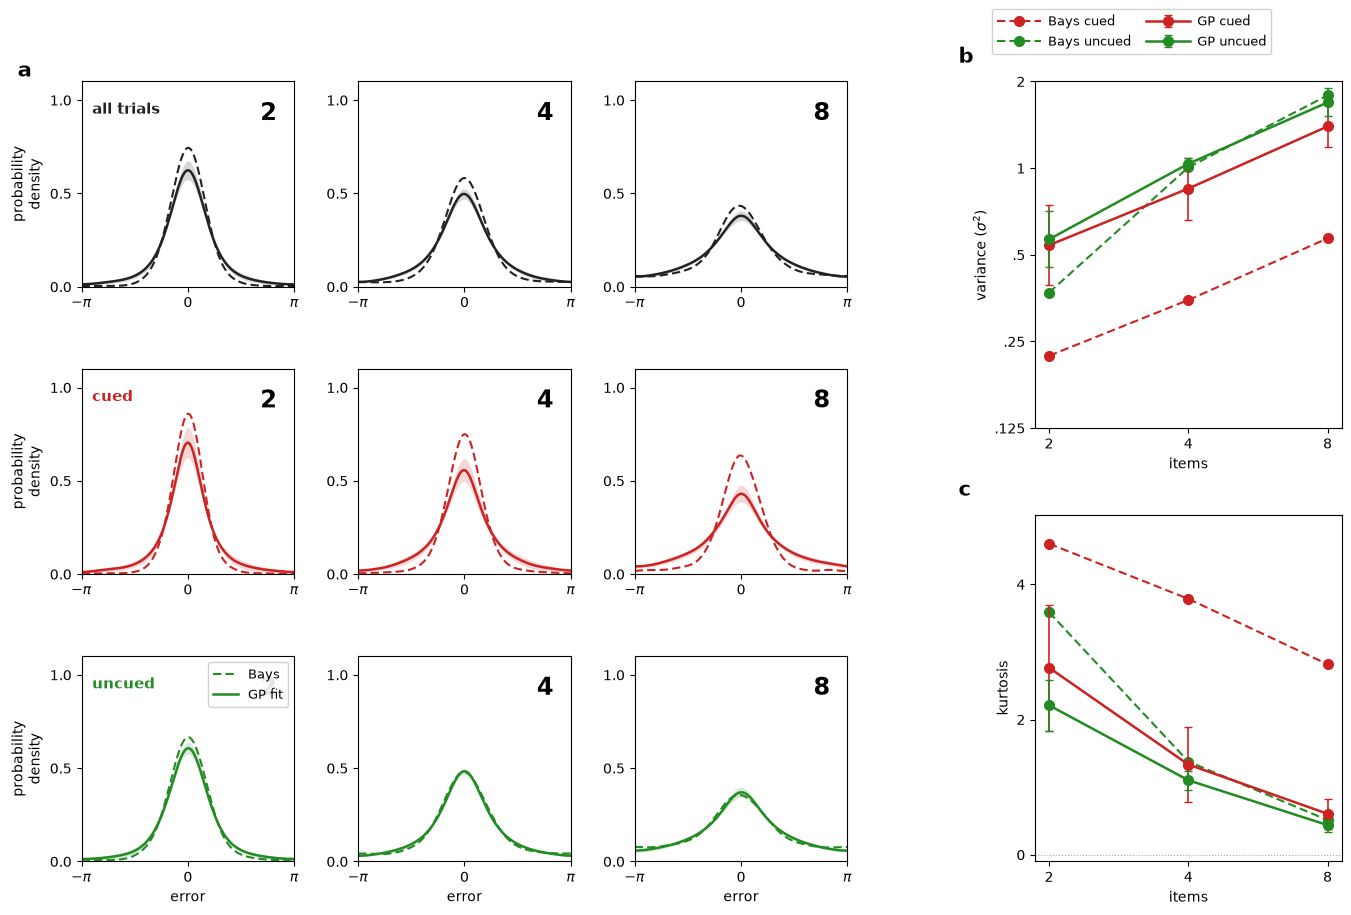

In [27]:
# === Plot Bays vs GP overlay (the headline comparison figure) ===
# Cued = red, uncued = green, all trials = black.  Bays = dashed, GP = solid.
# Original layout and style. The GP curves are now means over the population
# seeds, with 95% confidence bands (panel a) and error bars (panels b and c).
import math

RED, GREEN, BLACK = '#CC2222', '#228B22', '#222222'
ROW_COLOR = {'err_all': BLACK, 'err_cued': RED, 'err_uncued': GREEN}
theta_smooth = np.linspace(-np.pi, np.pi, 500)
KAPPA_BY_ROW = {'err_all': 10.0, 'err_cued': 18.0, 'err_uncued': 10.0}
row_configs = [('err_all',    'all trials'),
               ('err_cued',   'cued'),
               ('err_uncued', 'uncued')]

# ---- 1. KDEs: Bays once; GP per seed -> mean and 95% CI across seeds ----
# (bays_data[N]['err_all'] is built in the summary cell, as before.)
kde_bays, kde_gp = {}, {}
for key, _ in row_configs:
    for N in SET_SIZES:
        kde_bays[key, N] = vonmises_kde(bays_data[N][key], theta_smooth, KAPPA_BY_ROW[key])
        kde_gp[key, N] = mean_ci(np.array([
            vonmises_kde(r['pools'][N][key], theta_smooth, KAPPA_BY_ROW[key])
            for r in exp3_results]))

# Panel-a y-max from the KDE peaks of both models (including the GP band).
peak = max(max(float(v.max()) for v in kde_bays.values()),
           max(float(np.nanmax(v[2])) for v in kde_gp.values()))
if   peak <= 1.10: PANEL_A_YMAX, PANEL_A_YTICKS = 1.10, [0, 0.5, 1.0]
elif peak <= 1.65: PANEL_A_YMAX, PANEL_A_YTICKS = 1.65, [0, 0.5, 1.0, 1.5]
elif peak <= 2.20: PANEL_A_YMAX, PANEL_A_YTICKS = 2.20, [0, 0.5, 1.0, 1.5, 2.0]
elif peak <= 3.30: PANEL_A_YMAX, PANEL_A_YTICKS = 3.30, [0, 1.0, 2.0, 3.0]
else:              PANEL_A_YMAX, PANEL_A_YTICKS = peak * 1.10, None
print(f'Panel a peak={peak:.2f}, ymax={PANEL_A_YMAX:.2f}, ticks={PANEL_A_YTICKS}')

fig = plt.figure(figsize=(14, 10))
outer = gridspec.GridSpec(1, 2, width_ratios=[2.5, 1], wspace=0.35,
                          left=0.06, right=0.96, bottom=0.08, top=0.86)
gs_a  = gridspec.GridSpecFromSubplotSpec(3, len(SET_SIZES),
            subplot_spec=outer[0], hspace=0.4, wspace=0.3)
gs_bc = gridspec.GridSpecFromSubplotSpec(2, 1,
            subplot_spec=outer[1], hspace=0.25)

# ---------- Panel a ----------
first_ax = None
panel_a_legend_handles = None
for row, (key, label) in enumerate(row_configs):
    color = ROW_COLOR[key]
    for col, N in enumerate(SET_SIZES):
        ax = fig.add_subplot(gs_a[row, col])
        if first_ax is None: first_ax = ax

        m, lo, hi = kde_gp[key, N]
        ax.fill_between(theta_smooth, np.maximum(lo, 0.0), hi,
                        color=color, alpha=0.18, lw=0)
        h_bays, = ax.plot(theta_smooth, kde_bays[key, N], color=color, lw=1.5,
                          ls='--', dashes=(4, 2), label='Bays')
        h_gp,   = ax.plot(theta_smooth, m, color=color, lw=1.8,
                          ls='-', label='GP fit')

        ax.set_xlim(-np.pi, np.pi); ax.set_ylim(0, PANEL_A_YMAX)
        ax.set_xticks([-np.pi, 0, np.pi])
        ax.set_xticklabels([r'$-\pi$', '0', r'$\pi$'])
        if PANEL_A_YTICKS is not None:
            ax.set_yticks(PANEL_A_YTICKS)
        else:
            ax.yaxis.set_major_locator(plt.MaxNLocator(nbins=4, min_n_ticks=2))
        if row == 2: ax.set_xlabel('error')

        ax.text(0.92, 0.90, f'{N}', transform=ax.transAxes,
                fontsize=17, fontweight='bold', va='top', ha='right')

        if col == 0:
            ax.set_ylabel('probability\ndensity')
            ax.text(0.05, 0.90, label, transform=ax.transAxes,
                    fontsize=11, fontweight='bold', va='top', color=color)

        if row == 2 and col == 0:
            panel_a_legend_handles = (h_bays, h_gp)

fig.axes[-len(SET_SIZES)].legend(panel_a_legend_handles, ['Bays', 'GP fit'],
                                  fontsize=9, loc='upper right',
                                  frameon=True, framealpha=0.9)

first_ax.text(-0.30, 1.10, r'$\mathbf{a}$', transform=first_ax.transAxes,
              fontsize=15, fontweight='bold', va='top')

ns = np.array(SET_SIZES, dtype=float)


def _yerr(trip):
    m, lo, hi = trip
    return np.vstack([m - lo, hi - m])


# ---------- Panel b: variance (log2 x log2, as in the original) ----------
ax_b = fig.add_subplot(gs_bc[0])
vc_bays, vu_bays = summary['cued']['bays_var'], summary['uncued']['bays_var']
vc_gp,   vu_gp   = summary['cued']['var_ci'],   summary['uncued']['var_ci']   # geometric means

l_bays_c, = ax_b.plot(ns, vc_bays, 'o', color=RED,   lw=1.5, ms=7,
                      ls='--', dashes=(4, 2), label='Bays cued')
l_bays_u, = ax_b.plot(ns, vu_bays, 'o', color=GREEN, lw=1.5, ms=7,
                      ls='--', dashes=(4, 2), label='Bays uncued')
l_gp_c = ax_b.errorbar(ns, vc_gp[0], yerr=_yerr(vc_gp), fmt='o-', color=RED,
                       lw=1.8, ms=7, elinewidth=1.2, capsize=3, label='GP cued')
l_gp_u = ax_b.errorbar(ns, vu_gp[0], yerr=_yerr(vu_gp), fmt='o-', color=GREEN,
                       lw=1.8, ms=7, elinewidth=1.2, capsize=3, label='GP uncued')

ax_b.set_xscale('log', base=2); ax_b.set_yscale('log', base=2)
ax_b.set_xticks(SET_SIZES); ax_b.set_xticklabels([str(n) for n in SET_SIZES])

# Y-axis ticks: powers of 2 covering the data and error bars, no minor ticks.
all_v = np.concatenate([vc_bays, vu_bays, vc_gp[1], vc_gp[2], vu_gp[1], vu_gp[2]])
v_min, v_max = float(np.nanmin(all_v)), float(np.nanmax(all_v))
print(f'Panel b variance range: [{v_min:.3f}, {v_max:.3f}]')
lo_exp = int(math.floor(math.log2(max(v_min, 1e-3))))
hi_exp = int(math.ceil (math.log2(max(v_max, 1e-3))))
if hi_exp == lo_exp:                       # always at least two labelled ticks
    hi_exp += 1
major_ticks = [2.0 ** e for e in range(lo_exp, hi_exp + 1)]

def _fmt_var(v):
    if v >= 1: return f'{v:g}'
    s = f'{v:g}'
    return s.lstrip('0') if s.startswith('0.') else s

ax_b.set_yticks(major_ticks)
ax_b.set_yticklabels([_fmt_var(t) for t in major_ticks])
ax_b.yaxis.set_minor_locator(plt.NullLocator())
ax_b.set_ylim(2.0 ** lo_exp, 2.0 ** hi_exp)

ax_b.set_xlabel('items'); ax_b.set_ylabel(r'variance ($\sigma^2$)')
ax_b.text(-0.25, 1.10, r'$\mathbf{b}$', transform=ax_b.transAxes,
          fontsize=15, fontweight='bold', va='top')

# ---------- Panel c: kurtosis (linear y with a zero line, as in the original) ----------
ax_c = fig.add_subplot(gs_bc[1])
kc_bays, ku_bays = summary['cued']['bays_kurt'], summary['uncued']['bays_kurt']
kc_gp,   ku_gp   = summary['cued']['kurt_ci'],   summary['uncued']['kurt_ci']

ax_c.plot(ns, kc_bays, 'o', color=RED,   lw=1.5, ms=7, ls='--', dashes=(4, 2))
ax_c.plot(ns, ku_bays, 'o', color=GREEN, lw=1.5, ms=7, ls='--', dashes=(4, 2))
ax_c.errorbar(ns, kc_gp[0], yerr=_yerr(kc_gp), fmt='o-', color=RED,
              lw=1.8, ms=7, elinewidth=1.2, capsize=3)
ax_c.errorbar(ns, ku_gp[0], yerr=_yerr(ku_gp), fmt='o-', color=GREEN,
              lw=1.8, ms=7, elinewidth=1.2, capsize=3)

# Reference line at kurtosis = 0 (circular normal AND uniform both sit here).
ax_c.axhline(0, color='gray', lw=0.8, ls=':', alpha=0.7, zorder=0)

all_k = np.concatenate([kc_bays, ku_bays, kc_gp[1], kc_gp[2], ku_gp[1], ku_gp[2]])
k_min, k_max = float(np.nanmin(all_k)), float(np.nanmax(all_k))
k_pad = max(0.1, 0.10 * (k_max - k_min))
ax_c.set_ylim(min(k_min - k_pad, -0.1), k_max + k_pad)

ax_c.set_xscale('log', base=2)   # x stays log2 to match panel b
ax_c.set_xticks(SET_SIZES); ax_c.set_xticklabels([str(n) for n in SET_SIZES])
ax_c.yaxis.set_major_locator(plt.MaxNLocator(nbins=4, steps=[1, 2, 2.5, 5, 10], min_n_ticks=2))
ax_c.yaxis.set_minor_locator(plt.NullLocator())

ax_c.set_xlabel('items'); ax_c.set_ylabel('kurtosis')
ax_c.text(-0.25, 1.10, r'$\mathbf{c}$', transform=ax_c.transAxes,
          fontsize=15, fontweight='bold', va='top')
print(f'Panel c kurtosis range: [{k_min:.3f}, {k_max:.3f}]')

# Shared legend for b and c, above the column.
fig.legend(handles=[l_bays_c, l_bays_u, l_gp_c, l_gp_u],
           loc='center', bbox_to_anchor=(0.81, 0.91),
           fontsize=9, frameon=True, framealpha=0.9,
           ncol=2, columnspacing=1.2, handlelength=3.5, handletextpad=0.6)

saved = save_figure(fig, f'bays_fig3_gp_overlay_M{M}_{DISTRIBUTION}_{N_SEEDS}seeds',
                    thesis_name('fig_3'))
print('\nSaved:\n  ' + '\n  '.join(str(p) for p in saved))
print(f'  For the caption: panel a linear axes; panel b log axes (base 2) on both x and y; '
      f'panel c linear y-axis and log (base 2) x-axis. GP curves are means over {N_SEEDS} '
      f'population seeds (variance: geometric mean); bands and error bars are 95% CIs.')
plt.show()

In [28]:
# === Save results: per-seed parameters, summaries, tests, raw results ===
params_path = OUTPUT_DIR / 'exp3_parameters_by_seed.csv'
with open(params_path, 'w', newline='') as f:
    w = csv.writer(f)
    w.writerow(['seed_index', 'pop_seed', 'lambda', 'omega', 'gamma_total_hz', 'cv',
                'stage1_cost', 'stage1_heldout_cost']
               + [f'alpha_{N}' for N in SET_SIZES] + [f'alpha_cost_{N}' for N in SET_SIZES])
    for r in exp3_results:
        w.writerow([r['seed_index'], r['pop_seed'], r['lambda'], r['omega'], r['gamma_total'],
                    r['cv'], r['stage1_cost'], r['stage1_heldout_cost']]
                   + [r['stage2'][N]['alpha'] for N in SET_SIZES]
                   + [r['stage2'][N]['cost'] for N in SET_SIZES])

moments_path = OUTPUT_DIR / 'exp3_moments_summary.csv'
with open(moments_path, 'w', newline='') as f:
    w = csv.writer(f)
    w.writerow(['pool', 'set_size', 'n_seeds', 'bays_variance', 'model_variance_geomean',
                'variance_ci_lo', 'variance_ci_hi', 'bays_kurtosis', 'model_kurtosis_mean',
                'kurtosis_ci_lo', 'kurtosis_ci_hi'])
    for pool in POOLS:
        s_ = summary[pool]
        (gm, glo, ghi), (km, klo, khi) = s_['var_ci'], s_['kurt_ci']
        for j, N in enumerate(SET_SIZES):
            w.writerow([pool, N, N_SEEDS, s_['bays_var'][j], gm[j], glo[j], ghi[j],
                        s_['bays_kurt'][j], km[j], klo[j], khi[j]])

tests_path = OUTPUT_DIR / 'exp3_cued_vs_uncued_tests.csv'
with open(tests_path, 'w', newline='') as f:
    w = csv.writer(f)
    w.writerow(['set_size', 'ratio_uncued_over_cued_geomean', 'ci_lo', 'ci_hi', 't',
                'p_holm_one_sided', 'bays_ratio'])
    w.writerows(cued_vs_uncued)

raw_path = OUTPUT_DIR / 'exp3_seed_results.pkl'
with open(raw_path, 'wb') as f:
    pickle.dump({'config': _fit_config, 'N_SEEDS': N_SEEDS, 'SEED_BASES': SEED_BASES,
                 'noise_floor_stage1': NOISE_FLOOR_STAGE1,
                 'noise_floor_stage2': NOISE_FLOOR_STAGE2,
                 'results': exp3_results}, f)

print('Saved:')
for p in (params_path, moments_path, tests_path, raw_path):
    print(f'  {p}')

Saved:
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_3/20261021/sparse_sharp_100_gp_10seeds/182648/exp3_parameters_by_seed.csv
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_3/20261021/sparse_sharp_100_gp_10seeds/182648/exp3_moments_summary.csv
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_3/20261021/sparse_sharp_100_gp_10seeds/182648/exp3_cued_vs_uncued_tests.csv
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_3/20261021/sparse_sharp_100_gp_10seeds/182648/exp3_seed_results.pkl
